# Significance-Aware ENSO Analysis

A statistically honest companion to `analysis.ipynb`. Same clusters, but every
ENSO effect is tested against an **autocorrelation-preserving null** and shown
with **bootstrap confidence intervals**, because the real replication unit is
months / ENSO episodes (~17 El Niño episodes), *not* the ~16k days.

Design choices (see `src/enso_stats.py`):
- **Monthly** cluster-frequency series → correct unit of analysis.
- **Continuous, signed ONI** as predictor → uses magnitude + La Niña (more power).
- **Circular-rotation null** → preserves ENSO/cluster autocorrelation.
- **Max-statistic permutation** → controls the 15-cluster (and lag) multiplicity.
- **Year-block bootstrap** → confidence intervals on every effect.

**Structure:** Part I characterizes the regimes as a description of the region's climate; Part II tests ENSO as one driver of their frequency.

## Configuration — pick which trained model to analyse

In [1]:
import os, sys
if '..' not in sys.path:
    sys.path.append('..'); os.chdir('..')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

import src.inference as inf
from src.el_nino import read_enso_data
import src.enso_stats as es

# --- choose the run -------------------------------------------------------- #
# Seasonal (original):
# CONFIG = 'checkpoint/temperature-era-amazonia-15/params-temperature-era-amazonia-15.yaml'
# SAVE   = 'results/temperature-era-amazonia-15'
# Deseasonalised anomalies (new):
CONFIG = 'checkpoint/temperature-era-amazonia-15-anom/params-temperature-era-amazonia-15-anom.yaml'
SAVE   = 'results/temperature-era-amazonia-15-anom'

N_PERM, N_BOOT = 5000, 2000

## Load model, assign clusters, build the monthly series

In [2]:
params, dataset = inf.read_data(CONFIG, validation=True)
encoder, prot = inf.load_model(params)
F   = inf.get_model_results(read_path=SAVE, params=params, dataset=dataset,
                            encoder=encoder, prototypes=prot)[1]
F_v = inf.get_model_results(read_path=SAVE, params=params, dataset=dataset.validation_imgs,
                            encoder=encoder, prototypes=prot, validation=True)[1]
N = params['criterion']['num_proto']

cid   = torch.cat([F.argmax(1).cpu(), F_v.argmax(1).cpu()]).numpy()
dates = pd.to_datetime(list(dataset.time) + list(dataset.val_time))
df = pd.DataFrame({'cluster_id': cid, 'date': dates})

oni = read_enso_data(); oni.index.name = 'date_period'
monthly = es.build_monthly(df, oni, N)
print(f"months={len(monthly)}  years={monthly.year.nunique()}  "
      f"ENSO episodes={monthly.episode.nunique()}  ONI in [{monthly.ONI.min():.1f}, {monthly.ONI.max():.1f}]")
print(f"El Nino months={(monthly.Label=='El Niño').sum()}  "
      f"La Nina months={(monthly.Label=='La Niña').sum()}  Neutral={(monthly.Label=='Neutro').sum()}")

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_e7711dba3b5c50b3.pt


INFO:root:applied per-month per-cell deseasonalised standardisation (anomalies)
INFO:root:data loader created
Loaded E and F from results/temperature-era-amazonia-15-anom
Loaded E and F from results/temperature-era-amazonia-15-anom
months=531  years=45  ENSO episodes=35  ONI in [-1.8, 2.6]
El Nino months=67  La Nina months=91  Neutral=373


---
# Part I — Characterizing the climate regimes

Before asking about ENSO, we establish that the 15 learned clusters are a
meaningful, compact description of the region's climate: coherent spatial
patterns, day-to-day persistence, seasonal structure, and long-term trends.
ENSO (Part II) is then **one driver** of how often these regimes occur.

> The story adapts to `CONFIG`: on the **seasonal** model the regimes are the
> region's seasonal states; on the **-anom** model they are modes of
> temperature *variability* (anomaly patterns).

In [3]:
# ---------- shared setup for characterization & composites ----------
imgs   = dataset.imgs                          # (T,V,H,W) fields, native res (train)
cid_tr = F.argmax(1).cpu().numpy()
vars_names = params['data']['surf_vars']
V, H, W = imgs.shape[1:]
lat_lim = params['data']['lat_limit']; lon_lim = params['data']['lon_limit']
EXTENT = [min(lon_lim), max(lon_lim), min(lat_lim), max(lat_lim)]

# date-sorted daily sequence for persistence / transitions
df_day = df.copy(); df_day['date'] = pd.to_datetime(df_day['date'])
df_day = df_day.sort_values('date').reset_index(drop=True)

# per-day ENSO label on TRAIN days (used by the ENSO composites in Part II)
tr = pd.DataFrame({'cluster_id': cid_tr, 'date': pd.to_datetime(dataset.time)})
tr['mp'] = tr['date'].dt.to_period('M')
tr = tr.merge(oni[['Label', 'ONI']], left_on='mp', right_index=True, how='left')

def composite(mask):
    return imgs[np.asarray(mask, bool)].mean(0).numpy()          # (V,H,W)

def show_maps(maps, row_titles, sup, vabs=None):
    if vabs is None:
        vabs = np.percentile(np.abs(np.stack(maps)), 99)
    R = len(maps)
    fig, axes = plt.subplots(R, V, figsize=(4.2*V, 3.2*R), squeeze=False)
    for i, m in enumerate(maps):
        for v in range(V):
            ax = axes[i][v]
            im = ax.imshow(m[v], cmap='RdBu_r', vmin=-vabs, vmax=vabs,
                           extent=EXTENT, origin='upper', aspect='auto')
            if i == 0: ax.set_title(vars_names[v])
            if v == 0: ax.set_ylabel(row_titles[i], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.8, label='field value')
    fig.suptitle(sup, fontsize=13); plt.show()
    return vabs

dommean  = np.array([imgs[cid_tr == k].mean().item() for k in range(N)])   # cool->warm axis
freq_pct = np.array([(cid_tr == k).mean()*100 for k in range(N)])
order    = list(np.argsort(dommean))                                       # cool -> warm
print("regimes ordered cool->warm:", order)

regimes ordered cool->warm: [np.int64(14), np.int64(3), np.int64(10), np.int64(5), np.int64(11), np.int64(2), np.int64(9), np.int64(7), np.int64(12), np.int64(4), np.int64(13), np.int64(8), np.int64(1), np.int64(0), np.int64(6)]


## I.1  The regime vocabulary — mean spatial pattern of each cluster

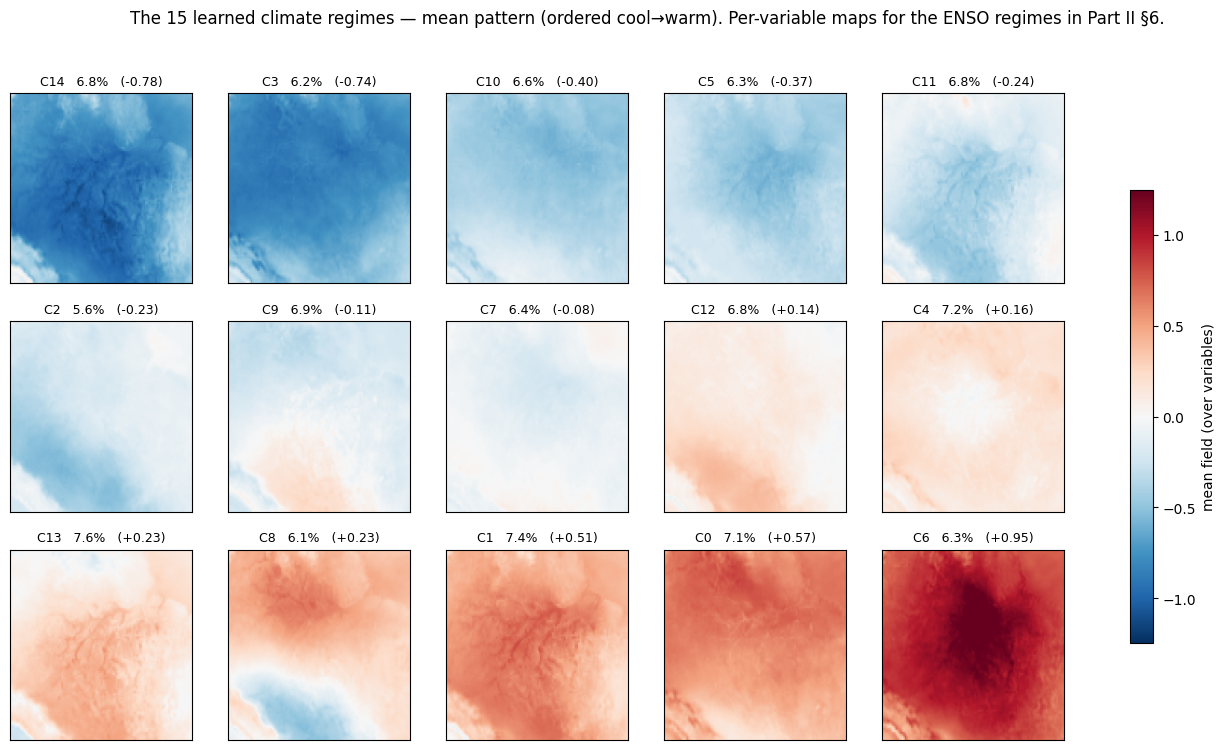

In [4]:
vabs = np.percentile(np.abs(np.stack([composite(cid_tr == k) for k in range(N)])), 99)
ncol = 5; nrow = int(np.ceil(N/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4*ncol, 2.8*nrow))
for ax, k in zip(axes.flat, order):
    m = composite(cid_tr == k).mean(0)                 # mean over variables
    im = ax.imshow(m, cmap='RdBu_r', vmin=-vabs, vmax=vabs, extent=EXTENT,
                   origin='upper', aspect='auto')
    ax.set_title(f"C{k}   {freq_pct[k]:.1f}%   ({dommean[k]:+.2f})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[N:]: ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.7, label='mean field (over variables)')
fig.suptitle('The 15 learned climate regimes — mean pattern (ordered cool→warm). '
             'Per-variable maps for the ENSO regimes in Part II §6.', fontsize=12)
plt.show()

## I.2  Regime summary table

In [5]:
season_of = {12:'DJF',1:'DJF',2:'DJF',3:'MAM',4:'MAM',5:'MAM',
             6:'JJA',7:'JJA',8:'JJA',9:'SON',10:'SON',11:'SON'}
dd = df_day.copy(); dd['season'] = dd['date'].dt.month.map(season_of)
dom_season = pd.crosstab(dd['cluster_id'], dd['season'], normalize='index').idxmax(1)

# mean regime duration (consecutive-day runs)
seq = df_day['cluster_id'].values
gap = (df_day['date'].diff().dt.days.values == 1)
runs = {k: [] for k in range(N)}; cur = seq[0]; L = 1
for i in range(1, len(seq)):
    if seq[i] == cur and gap[i]: L += 1
    else: runs[cur].append(L); cur = seq[i]; L = 1
runs[cur].append(L)
dur = {k: float(np.mean(runs[k])) for k in range(N)}

# long-term frequency trend (%/decade)
yf = monthly.groupby('year')[[f'f{k}' for k in range(N)]].mean()*100
yrs = yf.index.values.astype(float)
trend = {k: float(np.polyfit(yrs, yf[f'f{k}'].values, 1)[0]*10) for k in range(N)}

tbl = pd.DataFrame({
    'freq_%':       freq_pct.round(1),
    'mean_field':   dommean.round(2),
    'dom_season':   [dom_season[k] for k in range(N)],
    'mean_dur_d':   [round(dur[k], 1) for k in range(N)],
    'trend_%/dec':  [round(trend[k], 2) for k in range(N)],
}).rename_axis('cluster')
print(tbl.sort_values('mean_field').to_string())

         freq_%  mean_field dom_season  mean_dur_d  trend_%/dec
cluster                                                        
14          6.8       -0.78        SON         2.4        -4.11
3           6.2       -0.74        DJF         2.8        -3.11
10          6.6       -0.40        DJF         1.7        -2.45
5           6.3       -0.37        SON         1.5        -2.35
11          6.8       -0.24        JJA         1.7        -1.38
2           5.6       -0.23        JJA         1.5        -0.41
9           6.9       -0.11        MAM         1.6        -0.38
7           6.4       -0.08        MAM         1.5         0.39
12          6.8        0.14        JJA         1.6        -0.72
4           7.2        0.16        DJF         1.8         0.26
13          7.6        0.23        JJA         1.8         1.83
8           6.1        0.23        DJF         1.6         2.08
1           7.4        0.51        JJA         1.8         2.71
0           7.1        0.57        DJF  

## I.3  Seasonality — when each regime occurs

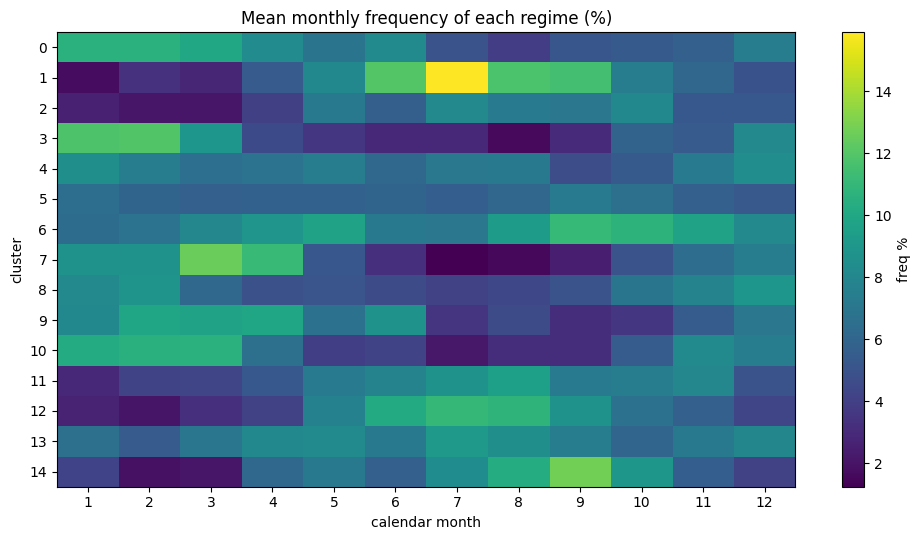

mean seasonal span (max-min monthly freq) = 7.3%  -> weak residual seasonality (deseasonalised: regimes are ~season-independent)


In [6]:
mfreq = (monthly.groupby('month')[[f'f{k}' for k in range(N)]].mean()*100)
mfreq.columns = range(N)
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(mfreq.T, aspect='auto', cmap='viridis')
ax.set_yticks(range(N)); ax.set_ylabel('cluster')
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_xlabel('calendar month')
ax.set_title('Mean monthly frequency of each regime (%)')
fig.colorbar(im, label='freq %'); plt.tight_layout(); plt.show()
span = (mfreq.max() - mfreq.min()).mean()
print(f"mean seasonal span (max-min monthly freq) = {span:.1f}%  "
      f"-> {'strong' if span>10 else 'weak'} residual seasonality "
      f"({'seasonal model' if span>10 else 'deseasonalised: regimes are ~season-independent'})")

## I.4  Persistence & transitions — regimes as coherent states

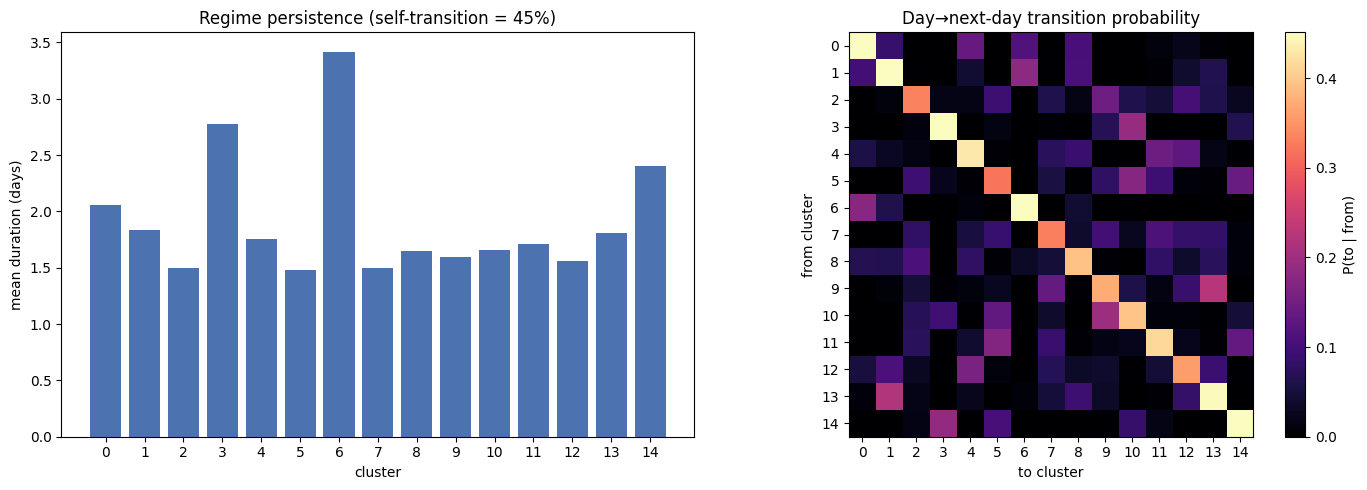

In [7]:
Tm = np.zeros((N, N))
for i in range(1, len(seq)):
    if gap[i]: Tm[seq[i-1], seq[i]] += 1
Tn = Tm / Tm.sum(1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(N), [dur[k] for k in range(N)], color='#4c72b0')
axes[0].set_xlabel('cluster'); axes[0].set_ylabel('mean duration (days)')
axes[0].set_title(f'Regime persistence (self-transition = {np.diag(Tn).mean():.0%})')
axes[0].set_xticks(range(N))
im = axes[1].imshow(Tn, cmap='magma', vmin=0, vmax=np.percentile(Tn, 98))
axes[1].set_title('Day→next-day transition probability')
axes[1].set_xlabel('to cluster'); axes[1].set_ylabel('from cluster')
axes[1].set_xticks(range(N)); axes[1].set_yticks(range(N))
fig.colorbar(im, ax=axes[1], label='P(to | from)'); plt.tight_layout(); plt.show()

## I.5  Long-term change — regime frequency through the decades

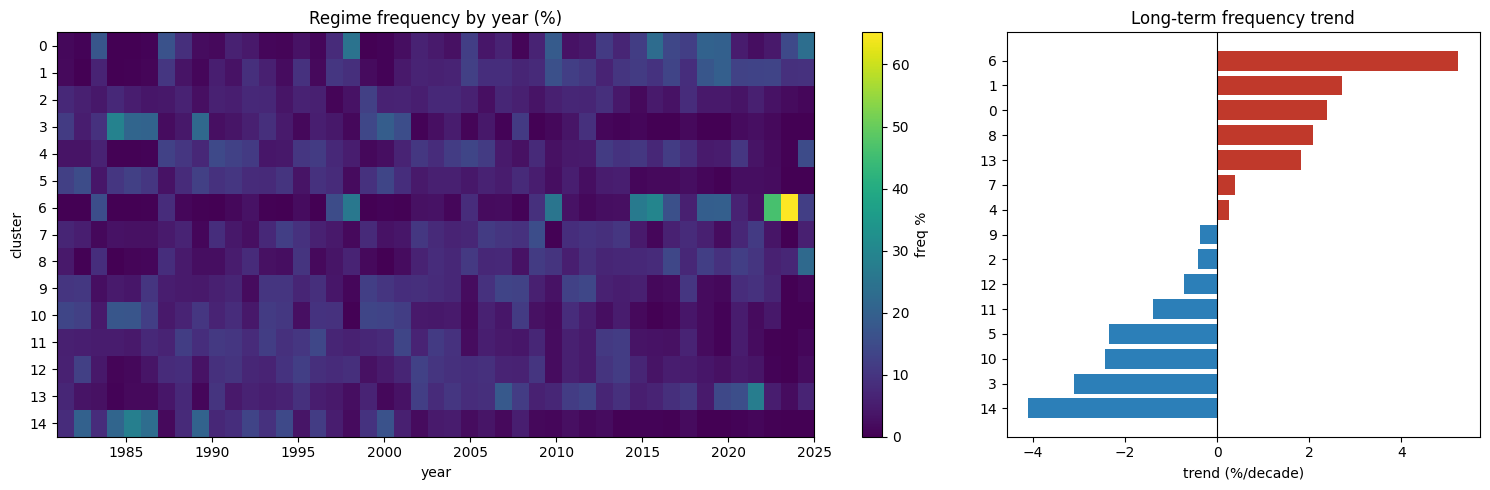

warming check: regimes getting MORE frequent (top) vs LESS (bottom):
  rising : {6: 5.25, 1: 2.71, 0: 2.39}
  falling: {14: -4.11, 3: -3.11, 10: -2.45}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios':[2,1]})
im = axes[0].imshow(yf.T, aspect='auto', cmap='viridis',
                    extent=[yrs.min(), yrs.max(), N-.5, -.5])
axes[0].set_yticks(range(N)); axes[0].set_ylabel('cluster'); axes[0].set_xlabel('year')
axes[0].set_title('Regime frequency by year (%)')
fig.colorbar(im, ax=axes[0], label='freq %')
ts = sorted(range(N), key=lambda k: trend[k])
axes[1].barh(range(N), [trend[k] for k in ts],
             color=['#2c7fb8' if trend[k] < 0 else '#c0392b' for k in ts])
axes[1].set_yticks(range(N)); axes[1].set_yticklabels(ts)
axes[1].axvline(0, color='k', lw=.8); axes[1].set_xlabel('trend (%/decade)')
axes[1].set_title('Long-term frequency trend')
plt.tight_layout(); plt.show()
print("warming check: regimes getting MORE frequent (top) vs LESS (bottom):")
print("  rising :", {k: round(trend[k],2) for k in ts[::-1][:3]})
print("  falling:", {k: round(trend[k],2) for k in ts[:3]})

## I.6  Physical sanity check — do warm/cool regimes hold in *every* month?

The composites above are in standardised anomaly units. Here we reconstruct the
**raw temperature** (not deseasonalised) and, for the warmest and coolest regimes,
show the mean domain-temperature departure from **each calendar month's**
climatology. This is the seasonally-fair test: a genuinely "warm" regime should
be warmer-than-normal in *every* month it occurs — not just warm because it
happens in summer. (Compositing raw temperature *without* stratifying by month
would just re-expose the seasonal cycle, so we stratify.)

In [9]:
from src.data_manager import Era5Dataset
# raw (non-deseasonalised) fields, same split & ordering as cid_tr
raw_ds = Era5Dataset(transform=None, surf_vars=vars_names, lat_lim=lat_lim, lon_lim=lon_lim,
                     split_val=True, val_years=params['data']['val_years'],
                     deseason_standardize=False)
raw_imgs = raw_ds.imgs                                     # (T,V,H,W) raw Kelvin
assert raw_imgs.shape[0] == len(cid_tr), "raw fields must align with cluster assignments"

month_tr = tr['date'].dt.month.values
dm_raw   = raw_imgs.mean((2, 3)).numpy()                   # (T,V) domain-mean raw temp
clim_m   = np.stack([dm_raw[month_tr == m].mean(0) for m in range(1, 13)])  # (12,V)

def month_departure(k):
    d = np.full((12, V), np.nan)
    for m in range(1, 13):
        s = (month_tr == m) & (cid_tr == k)
        if s.sum():
            d[m-1] = dm_raw[s].mean(0) - clim_m[m-1]
    return d

sanity = [order[-1], order[-2], order[1], order[0]]        # 2 warmest, 2 coolest
print("checking regimes (warm→cool):", sanity)

INFO:root:loaded cached daily tensor from ../data/era5/.daily_cache/daily_e7711dba3b5c50b3.pt
checking regimes (warm→cool): [np.int64(6), np.int64(0), np.int64(3), np.int64(14)]


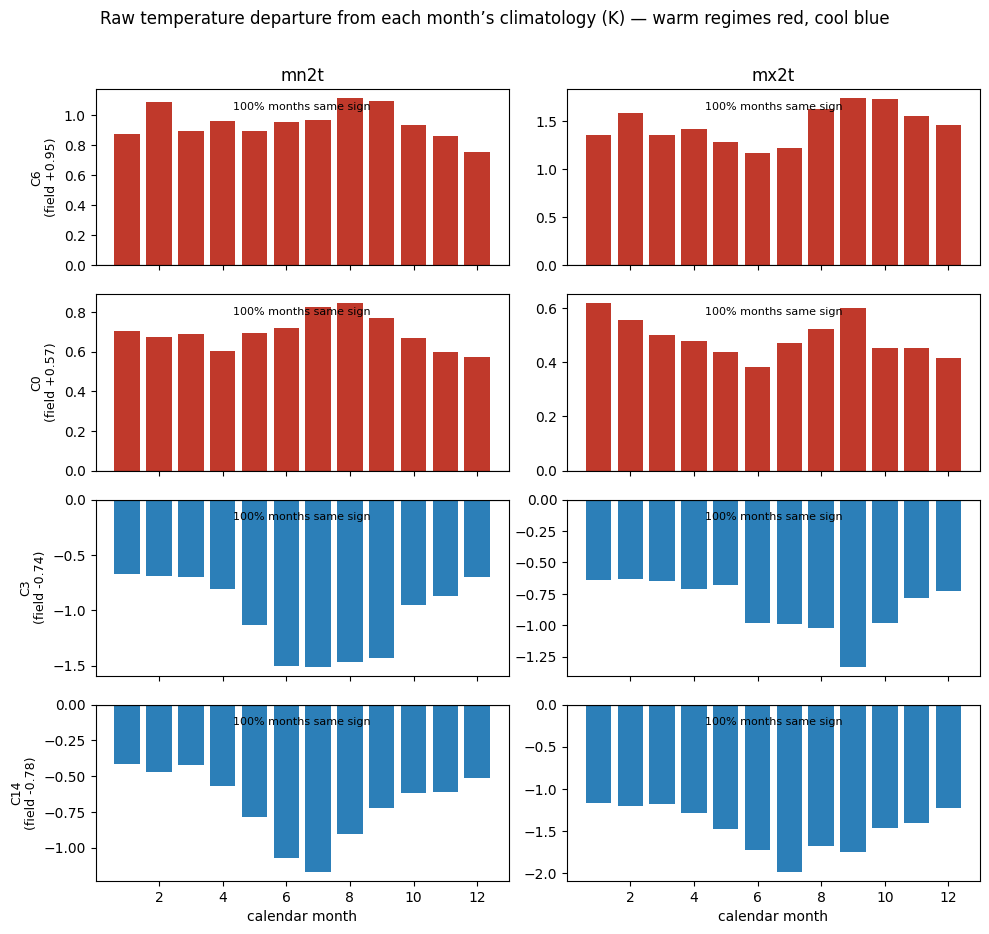

Consistency (fraction of months the departure keeps the regime's overall sign):
  C6: mn2t 100% (mean +0.95 K) | mx2t 100% (mean +1.46 K)
  C0: mn2t 100% (mean +0.70 K) | mx2t 100% (mean +0.49 K)
  C3: mn2t 100% (mean -1.04 K) | mx2t 100% (mean -0.84 K)
  C14: mn2t 100% (mean -0.69 K) | mx2t 100% (mean -1.46 K)


In [10]:
fig, axes = plt.subplots(len(sanity), V, figsize=(5*V, 2.3*len(sanity)),
                         sharex=True, squeeze=False)
for i, k in enumerate(sanity):
    d = month_departure(k)
    for v in range(V):
        ax = axes[i][v]
        ax.bar(range(1, 13), d[:, v],
               color=['#c0392b' if x > 0 else '#2c7fb8' for x in d[:, v]])
        ax.axhline(0, color='k', lw=.8)
        cons = np.nanmean(np.sign(d[:, v]) == np.sign(np.nanmean(d[:, v]))) * 100
        ax.text(.5, .93, f"{cons:.0f}% months same sign", transform=ax.transAxes,
                ha='center', va='top', fontsize=8)
        if i == 0: ax.set_title(vars_names[v])
        if v == 0: ax.set_ylabel(f"C{k}\n(field {dommean[k]:+.2f})", fontsize=9)
for v in range(V): axes[-1][v].set_xlabel('calendar month')
fig.suptitle('Raw temperature departure from each month’s climatology (K) — warm regimes red, cool blue',
             y=1.01)
plt.tight_layout(); plt.show()

print("Consistency (fraction of months the departure keeps the regime's overall sign):")
for k in sanity:
    d = month_departure(k)
    parts = [f"{vars_names[v]} {np.nanmean(np.sign(d[:,v])==np.sign(np.nanmean(d[:,v])))*100:.0f}%"
             f" (mean {np.nanmean(d[:,v]):+.2f} K)" for v in range(V)]
    print(f"  C{k}: " + " | ".join(parts))

---
# Part II — ENSO as one application

Having characterized the regimes, we now test how ENSO modulates their frequency,
using the significance-aware machinery below.

## 1. Omnibus gate — is there *any* ENSO signal?

One global test before looking at individual clusters. If this fails, per-cluster
"findings" are just multiple-comparison noise and should not be interpreted.

In [11]:
stat, p = es.omnibus_test(monthly, N, n_perm=N_PERM)
verdict = "SIGNAL: ONI is related to cluster occupancy" if p < 0.05 else \
          "NO GLOBAL SIGNAL: do not interpret individual clusters"
print(f"omnibus  sum(corr^2) = {stat:.3f}   p = {p:.4f}\n=> {verdict}")

omnibus  sum(corr^2) = 0.485   p = 0.0130
=> SIGNAL: ONI is related to cluster occupancy


## 2. Continuous-ONI response per cluster

Correlation between each cluster's monthly frequency and ONI (uses the full
signed gradient). Bars colored by significance:
**red = survives family-wise (FWER) correction**, orange = raw p<0.05 only,
grey = not significant. Whiskers = 95% year-block bootstrap CI.

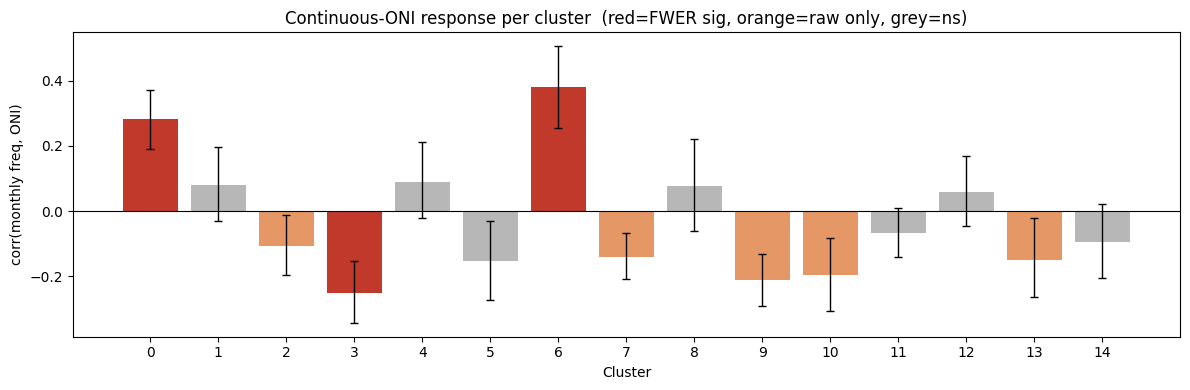

          corr  p_raw  p_fwer  ci_lo  ci_hi
cluster                                    
0        0.281  0.022   0.022  0.189  0.372
1        0.079  0.185   0.903 -0.029  0.196
2       -0.108  0.041   0.677 -0.196 -0.013
3       -0.252  0.008   0.029 -0.342 -0.153
4        0.089  0.214   0.830 -0.020  0.211
5       -0.152  0.065   0.326 -0.271 -0.030
6        0.381  0.004   0.011  0.255  0.505
7       -0.142  0.009   0.384 -0.209 -0.066
8        0.078  0.375   0.904 -0.061  0.222
9       -0.212  0.015   0.086 -0.291 -0.133
10      -0.195  0.021   0.132 -0.305 -0.084
11      -0.066  0.215   0.959 -0.140  0.011
12       0.060  0.334   0.985 -0.045  0.167
13      -0.150  0.018   0.339 -0.264 -0.020
14      -0.094  0.288   0.808 -0.204  0.021

raw p<0.05: 8/15  (expected ~0.8 by chance) | FWER<0.05: 3/15


In [12]:
resp = es.oni_response(monthly, N, n_perm=N_PERM)
lo, hi = es.bootstrap_ci_oni_corr(monthly, N, n_boot=N_BOOT)
resp['ci_lo'], resp['ci_hi'] = lo, hi

def sig_colors(p_fwer, p_raw):
    out = []
    for k in range(len(p_fwer)):
        if p_fwer[k] < 0.05:   out.append('#c0392b')
        elif p_raw[k] < 0.05:  out.append('#e59866')
        else:                  out.append('#b7b7b7')
    return out

fig, ax = plt.subplots(figsize=(12, 4))
c = sig_colors(resp.p_fwer.values, resp.p_raw.values)
ax.bar(resp.index, resp['corr'], color=c)
ax.errorbar(resp.index, resp['corr'],
            yerr=[resp['corr']-resp.ci_lo, resp.ci_hi-resp['corr']],
            fmt='none', ecolor='black', capsize=3, lw=1)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Cluster'); ax.set_ylabel('corr(monthly freq, ONI)')
ax.set_title('Continuous-ONI response per cluster  (red=FWER sig, orange=raw only, grey=ns)')
ax.set_xticks(range(N)); plt.tight_layout(); plt.show()

print(resp.round(3).to_string())
print(f"\nraw p<0.05: {(resp.p_raw<0.05).sum()}/{N}  "
      f"(expected ~{0.05*N:.1f} by chance) | FWER<0.05: {(resp.p_fwer<0.05).sum()}/{N}")

## 3. El Niño occurrence anomaly — the original plot, done honestly

Same quantity as `analysis.ipynb` section 4 ( P(k|El Niño) − P(k) ), but now with
95% bootstrap CIs and an autocorrelation-aware null. **A bar whose CI crosses 0
is not a reliable effect**, however tall it looks.

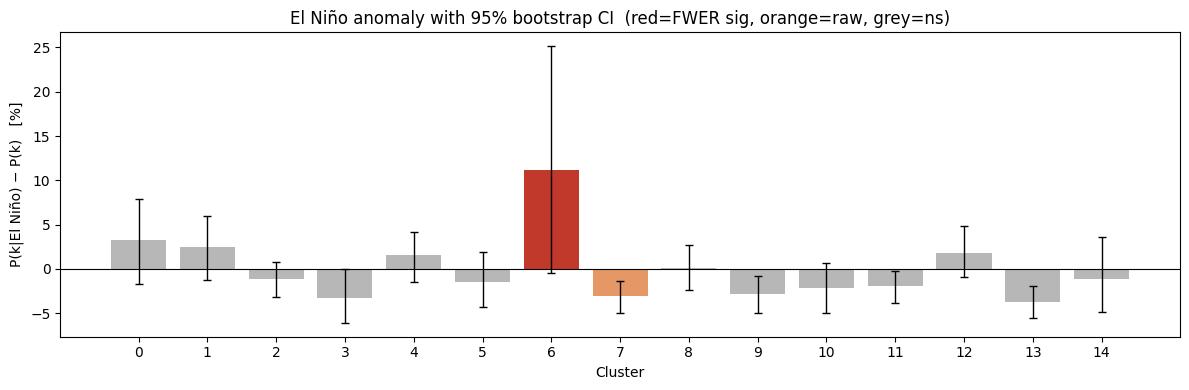

          anom  ci_lo  ci_hi  p_raw  p_fwer
cluster                                    
6        11.14  -0.46  25.14   0.05    0.05
13       -3.67  -5.55  -1.97   0.05    0.67
0         3.29  -1.74   7.86   0.23    0.77
3        -3.23  -6.08  -0.04   0.27    0.79
7        -3.04  -4.97  -1.40   0.05    0.83
9        -2.87  -4.96  -0.79   0.08    0.87
1         2.51  -1.27   6.01   0.28    0.94
10       -2.20  -4.97   0.71   0.27    0.96
11       -1.89  -3.80  -0.21   0.26    0.98
12        1.84  -0.87   4.84   0.23    0.98
4         1.59  -1.43   4.19   0.24    1.00
5        -1.44  -4.33   1.96   0.36    1.00
14       -1.10  -4.86   3.58   0.72    1.00
2        -1.08  -3.11   0.77   0.27    1.00
8         0.15  -2.36   2.71   0.93    1.00


In [13]:
an = es.elnino_anomaly(monthly, N, n_perm=N_PERM, n_boot=N_BOOT)
fig, ax = plt.subplots(figsize=(12, 4))
c = sig_colors(an.p_fwer.values, an.p_raw.values)
ax.bar(an.index, an['anom'], color=c)
ax.errorbar(an.index, an['anom'], yerr=[an['anom']-an.ci_lo, an.ci_hi-an['anom']],
            fmt='none', ecolor='black', capsize=3, lw=1)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Cluster'); ax.set_ylabel('P(k|El Niño) − P(k)   [%]')
ax.set_title('El Niño anomaly with 95% bootstrap CI  (red=FWER sig, orange=raw, grey=ns)')
ax.set_xticks(range(N)); plt.tight_layout(); plt.show()
print(an.reindex(an.anom.abs().sort_values(ascending=False).index).round(2).to_string())

## 4. Lagged response — cross-correlation instead of per-cell heatmaps

For each cluster, corr(monthly freq(t), ONI(t−lag)) across lags. Cells that
survive the **family-wise** max-statistic correction (over all clusters × lags)
are outlined in black — everything else is within noise.

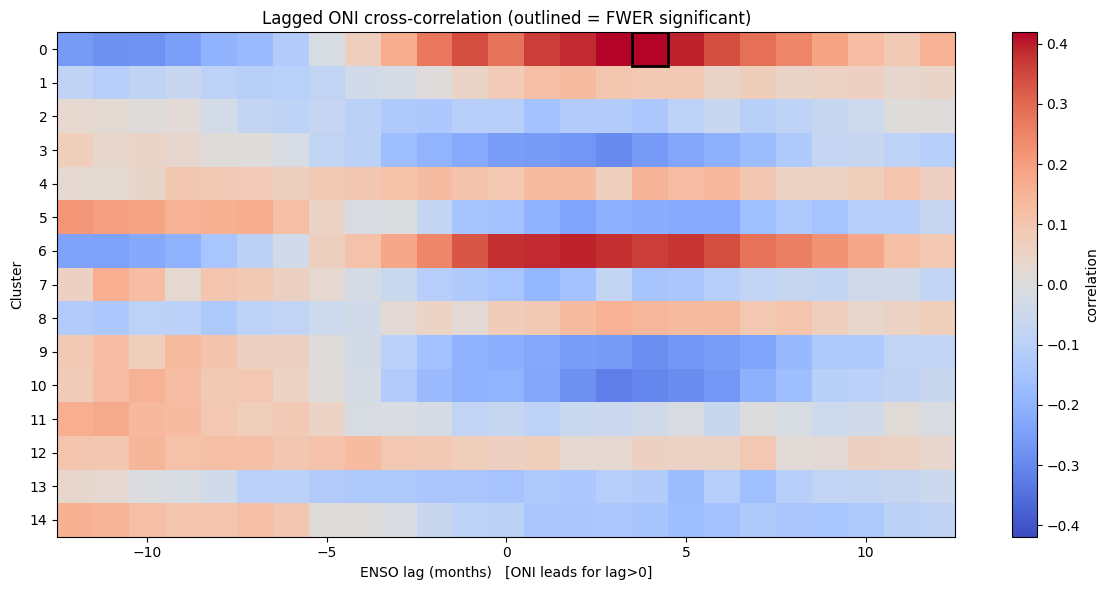

1 of 375 (cluster,lag) cells survive family-wise correction


In [14]:
lags, cc, pf = es.lag_crosscorr(monthly, N, max_lag=12, n_perm=N_PERM)
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(cc, aspect='auto', cmap='coolwarm', vmin=-np.abs(cc).max(), vmax=np.abs(cc).max(),
               extent=[lags[0]-.5, lags[-1]+.5, N-.5, -.5])
for k in range(N):
    for j, L in enumerate(lags):
        if pf[k, j] < 0.05:
            ax.add_patch(plt.Rectangle((L-.5, k-.5), 1, 1, fill=False, edgecolor='k', lw=2))
ax.set_xlabel('ENSO lag (months)   [ONI leads for lag>0]'); ax.set_ylabel('Cluster')
ax.set_yticks(range(N)); ax.set_title('Lagged ONI cross-correlation (outlined = FWER significant)')
fig.colorbar(im, ax=ax, label='correlation'); plt.tight_layout(); plt.show()
nsig = int((pf < 0.05).sum())
print(f"{nsig} of {pf.size} (cluster,lag) cells survive family-wise correction")

## 5. Robustness — does the signal reproduce across time?

Per-cluster ONI correlation computed on the first vs second half of the record.
Points near the diagonal = stable (real) effects; scatter = noise. Only trust
clusters that are significant **and** land near the diagonal.

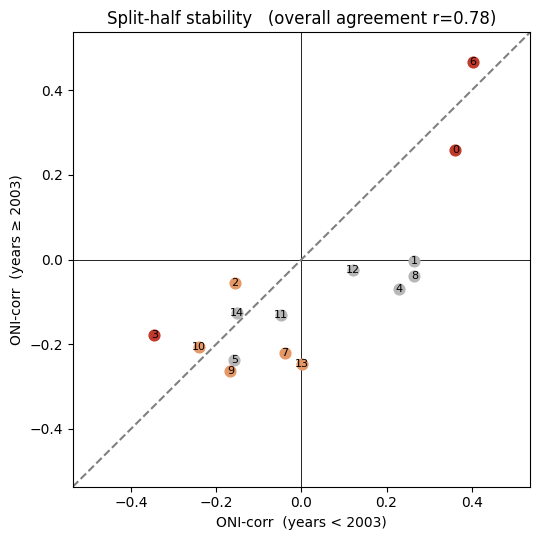

In [15]:
sh, r, mid = es.split_half(monthly, N)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.axhline(0, color='k', lw=.6); ax.axvline(0, color='k', lw=.6)
lim = np.abs(sh.values).max()*1.15
ax.plot([-lim, lim], [-lim, lim], '--', color='grey')
for k in range(N):
    col = '#c0392b' if resp.p_fwer[k] < 0.05 else ('#e59866' if resp.p_raw[k] < 0.05 else '#b7b7b7')
    ax.scatter(sh.corr_firsthalf[k], sh.corr_secondhalf[k], color=col, s=60, zorder=3)
    ax.annotate(str(k), (sh.corr_firsthalf[k], sh.corr_secondhalf[k]), fontsize=8,
                ha='center', va='center')
ax.set_xlabel(f'ONI-corr  (years < {mid})'); ax.set_ylabel(f'ONI-corr  (years ≥ {mid})')
ax.set_title(f'Split-half stability   (overall agreement r={r:.2f})')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); plt.tight_layout(); plt.show()

## 6. What do the ENSO-linked regimes look like? (physical interpretation)

We composite the **deseasonalised temperature anomaly** fields (native resolution,
training days) for the clusters that passed every statistical gate. This shows the
actual spatial temperature-anomaly pattern each ENSO-linked regime represents.
Warm colors = warmer-than-normal for that calendar month; blue = cooler-than-normal.

In [16]:
# robust = clusters passing FWER in Part II §2 (fallback: strongest |corr|)
robust = [k for k in range(N) if resp.p_fwer[k] < 0.05]
if not robust:
    robust = list(resp['corr'].abs().sort_values(ascending=False).index[:3])
print('ENSO-linked regimes:', robust,
      '| ONI corr:', {k: round(float(resp['corr'][k]), 2) for k in robust})

ENSO-linked regimes: [0, 3, 6] | ONI corr: {0: 0.28, 3: -0.25, 6: 0.38}


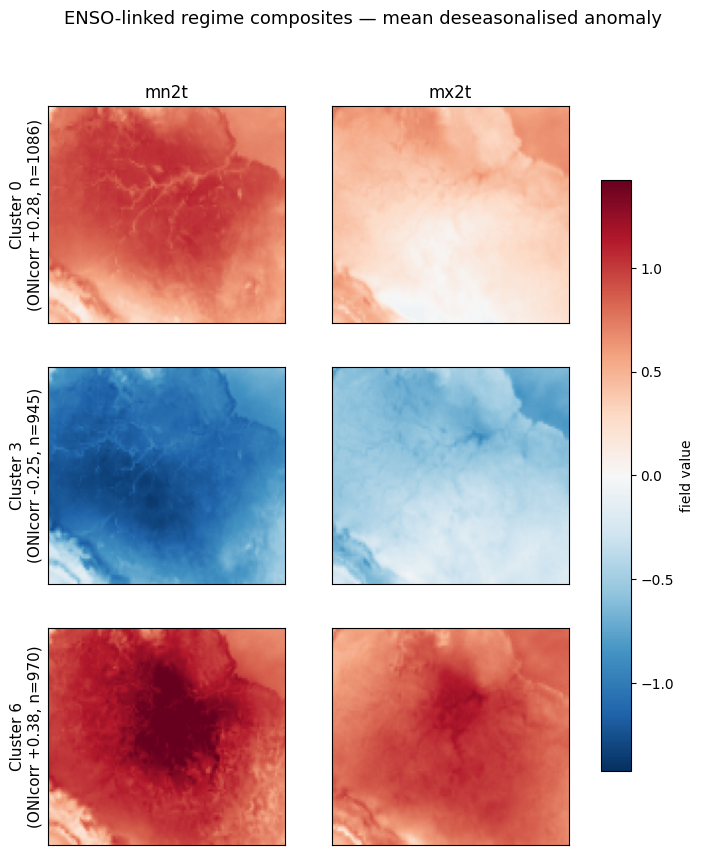

In [17]:
# Regime composite anomaly maps (robust clusters)
maps = [composite(cid_tr == k) for k in robust]
titles = [f"Cluster {k}\n(ONIcorr {resp['corr'][k]:+.2f}, n={int((cid_tr==k).sum())})" for k in robust]
vabs = show_maps(maps, titles, 'ENSO-linked regime composites — mean deseasonalised anomaly')

## 7. Do the regimes match the ENSO fingerprint?

Left/middle: the **direct ENSO signature** — mean anomaly on El Niño vs La Niña
months. Right column logic: we then measure the **spatial correlation** between
each cluster's composite (§6) and the El Niño composite. Clusters that are
positively ONI-correlated should look like El Niño; negatively-correlated ones
should look like La Niña (≈ anti-correlated with the El Niño map).

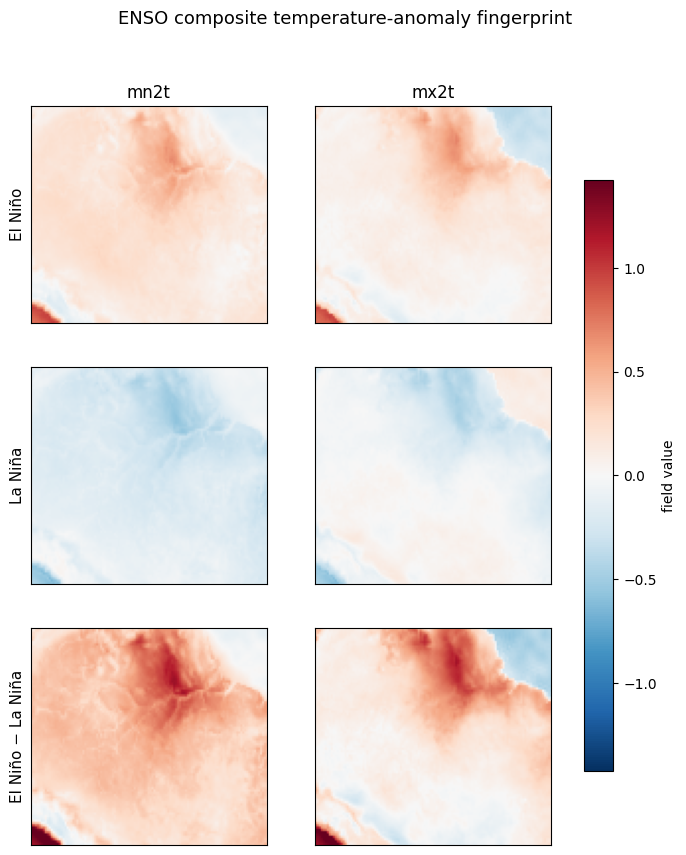

np.float32(1.4246631)

In [18]:
el_map = composite(tr.Label.values == 'El Niño')
ln_map = composite(tr.Label.values == 'La Niña')
show_maps([el_map, ln_map, el_map - ln_map],
          ['El Niño', 'La Niña', 'El Niño − La Niña'],
          'ENSO composite temperature-anomaly fingerprint', vabs=vabs)

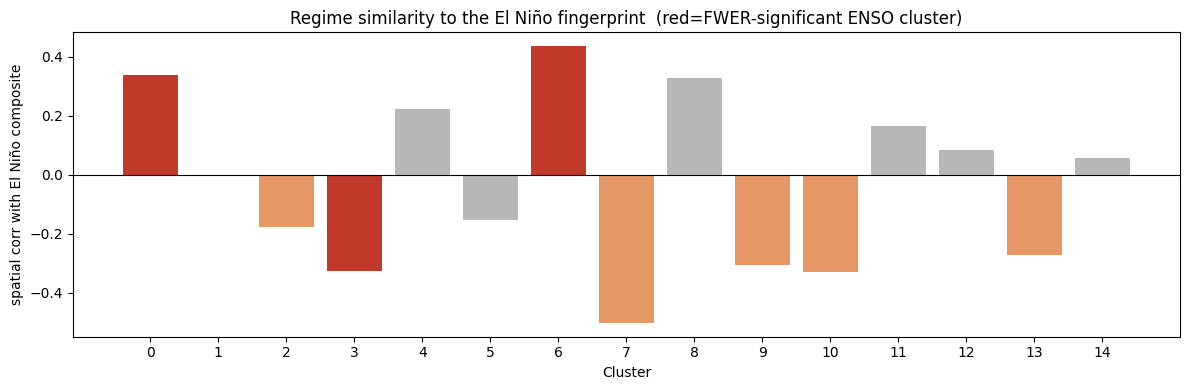

cluster 0: ONIcorr=+0.28, spatial-sim to ElNiño=+0.34 -> El Niño-like
cluster 3: ONIcorr=-0.25, spatial-sim to ElNiño=-0.33 -> La Niña-like
cluster 6: ONIcorr=+0.38, spatial-sim to ElNiño=+0.44 -> El Niño-like


In [19]:
# Spatial similarity of every cluster's composite to the El Niño fingerprint
def spatial_corr(a, b):
    a = a.ravel() - a.mean(); b = b.ravel() - b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

el_flat = el_map  # (V,H,W)
sim = np.array([spatial_corr(composite(cid_tr == k), el_flat) for k in range(N)])
fig, ax = plt.subplots(figsize=(12, 4))
cols = sig_colors(resp.p_fwer.values, resp.p_raw.values)
ax.bar(range(N), sim, color=cols)
ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('Cluster'); ax.set_ylabel('spatial corr with El Niño composite')
ax.set_title('Regime similarity to the El Niño fingerprint  (red=FWER-significant ENSO cluster)')
ax.set_xticks(range(N)); plt.tight_layout(); plt.show()
for k in robust:
    kind = 'El Niño-like' if sim[k] > 0 else 'La Niña-like'
    print(f"cluster {k}: ONIcorr={resp['corr'][k]:+.2f}, spatial-sim to ElNiño={sim[k]:+.2f} -> {kind}")

## 8. How the regimes track ENSO through time

For each robust regime: 12-month rolling occurrence frequency (blue) against the
ONI index (grey), with El Niño periods shaded. Co-movement here is the temporal
counterpart of the §2 correlation.

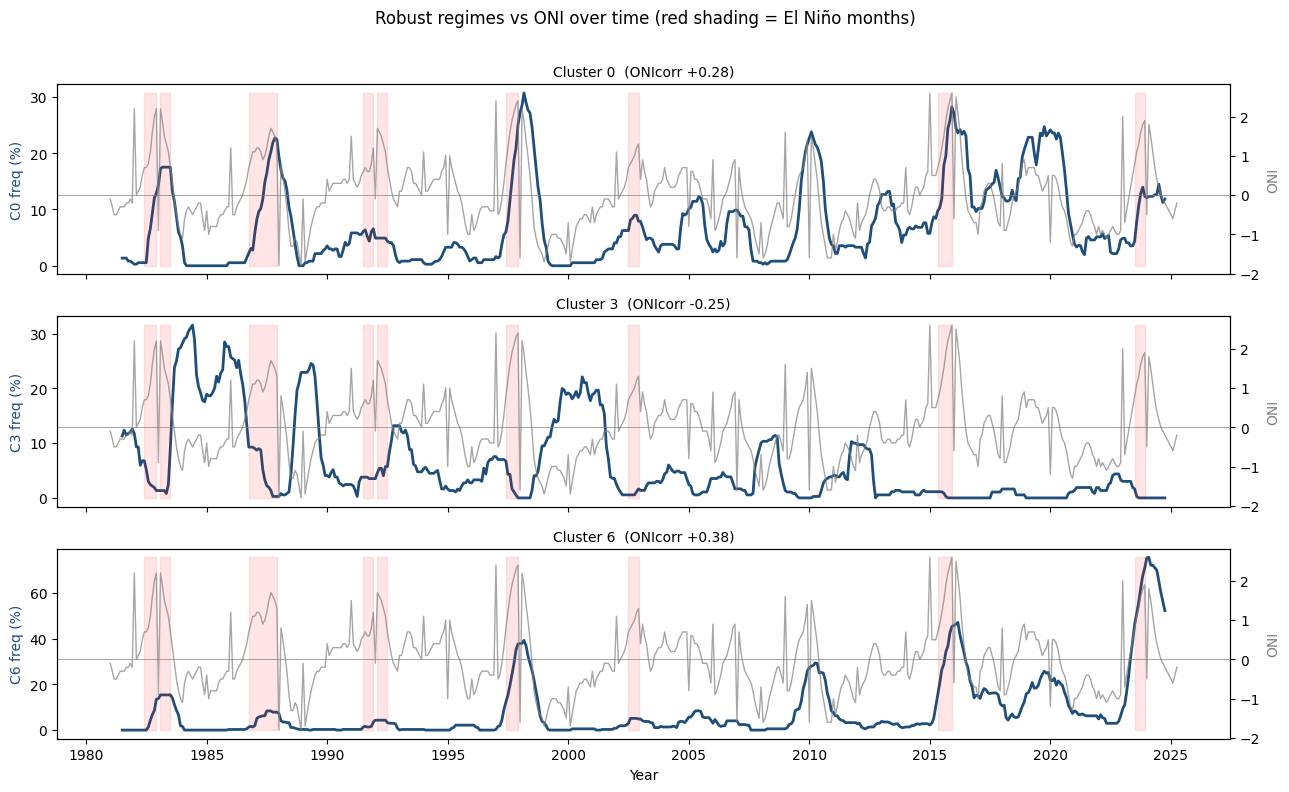

In [20]:
mon = monthly.copy(); mon['t'] = mon.index.to_timestamp()
fig, axes = plt.subplots(len(robust), 1, figsize=(13, 2.6*len(robust)), sharex=True, squeeze=False)
for i, k in enumerate(robust):
    ax = axes[i][0]
    freq = mon[f'f{k}'].rolling(12, center=True).mean() * 100
    ax.plot(mon['t'], freq, color='#1f4e79', lw=2, label=f'cluster {k} freq (12-mo)')
    ax.set_ylabel(f'C{k} freq (%)', color='#1f4e79')
    ax2 = ax.twinx()
    ax2.plot(mon['t'], mon['ONI'], color='grey', lw=1, alpha=.7)
    ax2.axhline(0, color='grey', lw=.5); ax2.set_ylabel('ONI', color='grey')
    ax2.fill_between(mon['t'], mon['ONI'].min(), mon['ONI'].max(),
                     where=(mon['Label'] == 'El Niño').values, color='red', alpha=.10)
    ax.set_title(f"Cluster {k}  (ONIcorr {resp['corr'][k]:+.2f})", fontsize=10)
axes[-1][0].set_xlabel('Year')
fig.suptitle('Robust regimes vs ONI over time (red shading = El Niño months)', y=1.01)
plt.tight_layout(); plt.show()

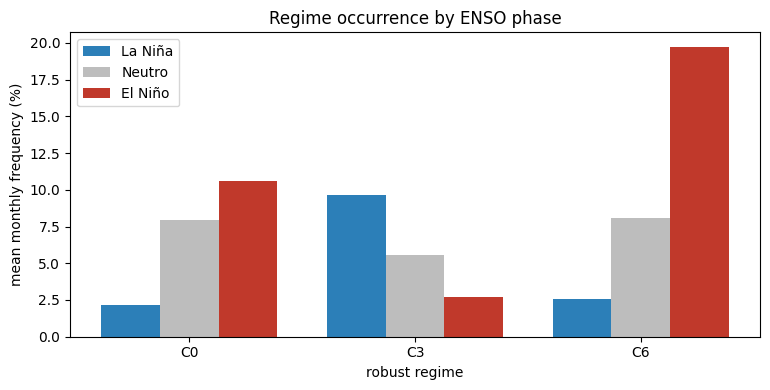

           f0   f3    f6
Label                   
La Niña   2.2  9.7   2.5
Neutro    8.0  5.6   8.1
El Niño  10.6  2.7  19.7


In [21]:
# Regime frequency by ENSO phase — how much more/less common under each phase
order = ['La Niña', 'Neutro', 'El Niño']
phase_freq = (monthly.groupby('Label')[[f'f{k}' for k in range(N)]].mean() * 100).reindex(order)
x = np.arange(len(robust)); w = 0.26
fig, ax = plt.subplots(figsize=(1.6*len(robust)+3, 4))
for j, ph in enumerate(order):
    ax.bar(x + (j-1)*w, [phase_freq.loc[ph, f'f{k}'] for k in robust], w,
           label=ph, color=['#2c7fb8', '#bdbdbd', '#c0392b'][j])
ax.set_xticks(x); ax.set_xticklabels([f'C{k}' for k in robust])
ax.set_ylabel('mean monthly frequency (%)'); ax.set_xlabel('robust regime')
ax.set_title('Regime occurrence by ENSO phase'); ax.legend(); plt.tight_layout(); plt.show()
print(phase_freq[[f'f{k}' for k in robust]].round(1).to_string())

## Summary — what can you conclude?

Read it in this order:
1. **Omnibus** significant? If not, stop — no ENSO story.
2. Trust a cluster only if it is **FWER-significant (red)** in §2, its **CI excludes 0** in §3, **and** it sits **near the diagonal** in §5.
3. The **continuous-ONI** test (§2) is the primary, most powerful result; the binary El Niño anomaly (§3) is the familiar view but weaker.
4. With ~17 El Niño episodes, expect **few** robust clusters — that is the honest ceiling of this dataset, not a modelling failure. To raise it: add precipitation, or extend the ERA5 record.
5. **Physical read (§6–§8):** interpret only the robust regimes — their composite anomaly maps, similarity to the El Niño/La Niña fingerprint, and time-tracking against ONI tell you *what* ENSO does to Amazonian temperature and *how strongly*.